In [ ]:
# Defines function to parse the cleaned map to dict

import ast
import re

def parse_mappings(filepath):
    with open(filepath, "r", encoding="utf-8") as f:
        text = f.read()

    result = {}

    # Match each Columns declaration and its mapping block
    pattern = r"Columns:\s*(\[.*?\])\s*'[^']*':\s*\{(.*?)\}"

    for columns_str, mapping_str in re.findall(
        pattern, text, flags=re.DOTALL
    ):
        columns = ast.literal_eval(columns_str)

        # Parse key:value pairs
        mapping = {}
        for key, value in re.findall(
            r"([^,\s]+)\s*:\s*(\d+)\s*,?", mapping_str
        ):
            mapping[key] = int(value)

        for column in columns:
            result[column] = mapping

    return result

In [ ]:
import pandas as pd
df_raw = pd.read_csv('train.csv')
df = df_raw.copy()

In [ ]:
# Limpa colunas desnecessárias
colunas_remocao = [
    'Utilities',
    'Street',
    'Condition1',
    'Condition2',
    'RoofMatl',
    'Heating',
    'PoolQC',
    'Exterior1st',
    'Exterior2nd',
    'SaleType'
]
df = df.drop(columns=colunas_remocao)

In [ ]:
# Mapeamento da coluna MSSubClass para descrições textuais
mssubclass_map = {
    20: '1-STORY 1946 & NEWER ALL STYLES',
    30: '1-STORY 1945 & OLDER',
    40: '1-STORY W/FINISHED ATTIC ALL AGES',
    45: '1-1/2 STORY - UNFINISHED ALL AGES',
    50: '1-1/2 STORY FINISHED ALL AGES',
    60: '2-STORY 1946 & NEWER',
    70: '2-STORY 1945 & OLDER',
    75: '2-1/2 STORY ALL AGES',
    80: 'SPLIT OR MULTI-LEVEL',
    85: 'SPLIT FOYER',
    90: 'DUPLEX - ALL STYLES AND AGES',
    120: '1-STORY PUD (Planned Unit Development) - 1946 & NEWER',
    150: '1-1/2 STORY PUD - ALL AGES',
    160: '2-STORY PUD - 1946 & NEWER',
    180: 'PUD - MULTILEVEL - INCL SPLIT LEV/FOYER',
    190: '2 FAMILY CONVERSION - ALL STYLES AND AGES',
}
df['MSSubClass'] = df['MSSubClass'].map(mssubclass_map)

In [ ]:
# Criação de coluna boolean para existência da garagem
df['GarageYrBlt_exists'] = df['GarageYrBlt'].notna().astype(int)

In [ ]:
from sklearn.model_selection import train_test_split

# Separação das variáveis explicativas e variável alvo
X = df.drop(columns=['Id', 'SalePrice'])
y = df['SalePrice']

# Divide os dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

In [ ]:
# Colunas em que o nulo representa ausência do recurso
colunas_sem_recurso = [
    'Electrical',
    'Alley',
    'MasVnrType',
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'FireplaceQu',
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'Fence',
    'MiscFeature'
]

# Substitui os nulos pela categoria "None"
for coluna in colunas_sem_recurso:
    if coluna in X_train.columns:
        X_train[coluna] = X_train[coluna].fillna('None')
        X_test[coluna] = X_test[coluna].fillna('None')

In [ ]:
from sklearn.impute import SimpleImputer

# Identifica as colunas numéricas
num_columns = X_train.select_dtypes(include='number').columns

# Inicializa o imputador
imputer = SimpleImputer(strategy='mean')

# Ajusta no treino e transforma
X_train[num_columns] = imputer.fit_transform(X_train[num_columns])

# Aplica os mesmos valores de imputação no teste
X_test[num_columns] = imputer.transform(X_test[num_columns])

In [ ]:
# - Transforme as colunas ordinais em números (Ex: {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}; )
mappings = parse_mappings("possible_values_map_clean.txt")
for column, mapping in mappings.items():
    if column in X_train.columns:
        X_train[column] = X_train[column].map(mapping)
        X_test[column] = X_test[column].map(mapping)

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Identifica as colunas categóricas restantes
cat_columns = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns

# Inicializa o encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Ajusta no treino e transforma
X_train_cat = encoder.fit_transform(X_train[cat_columns])

# Aplica a mesma codificação no teste
X_test_cat = encoder.transform(X_test[cat_columns])

In [ ]:
from sklearn.preprocessing import StandardScaler

# Remove as colunas categóricas originais
X_train_num = X_train.drop(columns=cat_columns)
X_test_num = X_test.drop(columns=cat_columns)

# Identifica as colunas numéricas que devem ser normalizadas
scale_columns = [
    col for col in X_train_num.columns
    if col != 'CentralAir'
    and col != 'GarageYrBlt_exists'
]

# Inicializa o normalizador
scaler = StandardScaler()

# Ajusta no treino e transforma
X_train_num_scaled = X_train_num.copy()
X_test_num_scaled = X_test_num.copy()

X_train_num_scaled[scale_columns] = scaler.fit_transform(
    X_train_num[scale_columns]
)

# Aplica os parâmetros do treino ao teste
X_test_num_scaled[scale_columns] = scaler.transform(
    X_test_num[scale_columns]
)

In [ ]:
import numpy as np

# Combina os conjuntos
X_train_final = np.concatenate(
    [X_train_num_scaled.to_numpy(), X_train_cat], axis=1
)

X_test_final = np.concatenate(
    [X_test_num_scaled.to_numpy(), X_test_cat], axis=1
)

print("Treino:", X_train_final.shape)
print("Teste:", X_test_final.shape)

In [ ]:
# Transforma os preços com logaritmo natural
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# Padroniza o alvo usando apenas os dados de treino
y_scaler = StandardScaler()

y_train_final = y_scaler.fit_transform(
    y_train_log.to_numpy().reshape(-1, 1)
).ravel()

y_test_final = y_scaler.transform(
    y_test_log.to_numpy().reshape(-1, 1)
).ravel()

print("Treino:", y_train_final.shape)
print("Teste:", y_test_final.shape)

In [ ]:
print("X_train:", X_train_final.shape)
print("X_test:", X_test_final.shape)

print("y_train:", y_train_final.shape)
print("y_test:", y_test_final.shape)

print("NaN em X_train:", np.isnan(X_train_final).sum())
print("NaN em X_test:", np.isnan(X_test_final).sum())

print("Inf em X_train:", np.isinf(X_train_final).sum())
print("Inf em X_test:", np.isinf(X_test_final).sum())

In [ ]:
import torch

# Define o tipo de dado e converte para tensores
X_train_tensor = torch.tensor(
    X_train_final, dtype=torch.float32
)
X_test_tensor = torch.tensor(
    X_test_final, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_final, dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test_final, dtype=torch.float32
).reshape(-1, 1)

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("X_test:", X_test_tensor.shape)
print("y_test:", y_test_tensor.shape)

In [43]:
import torch.nn as nn

class ModeloCasasMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# Instancia a rede
model = ModeloCasasMLP(
    input_size=X_train_tensor.shape[1]
)

print(model)


ModeloCasasMLP(
  (network): Sequential(
    (0): Linear(in_features=169, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [44]:
import torch.optim as optim

# Função de perda para regressão
criterion = nn.MSELoss()

# Otimizador
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Função de perda:", criterion)
print("Otimizador:", optimizer)

Função de perda: MSELoss()
Otimizador: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [45]:
# Treinamento com Early Stopping  
# Treinamento com Early Stopping  import copy
# Treinamento com Early Stopping  import torch
# Treinamento com Early Stopping  import matplotlib.pyplot as plt
# Treinamento com Early Stopping  
# Treinamento com Early Stopping  num_epochs = 200
# Treinamento com Early Stopping  patience = 15
# Treinamento com Early Stopping  min_delta = 1e-5
# Treinamento com Early Stopping  
# Treinamento com Early Stopping  train_losses = []
# Treinamento com Early Stopping  test_losses = []
# Treinamento com Early Stopping  
# Treinamento com Early Stopping  best_test_loss = float("inf")
# Treinamento com Early Stopping  best_epoch = 0
# Treinamento com Early Stopping  best_model_state = None
# Treinamento com Early Stopping  epochs_without_improvement = 0
# Treinamento com Early Stopping  
# Treinamento com Early Stopping  for epoch in range(num_epochs):
# Treinamento com Early Stopping      # Treinamento
# Treinamento com Early Stopping      model.train()
# Treinamento com Early Stopping      optimizer.zero_grad()
# Treinamento com Early Stopping  
# Treinamento com Early Stopping      y_pred_train = model(X_train_tensor)
# Treinamento com Early Stopping      train_loss = criterion(y_pred_train, y_train_tensor)
# Treinamento com Early Stopping  
# Treinamento com Early Stopping      train_loss.backward()
# Treinamento com Early Stopping      optimizer.step()
# Treinamento com Early Stopping  
# Treinamento com Early Stopping      train_losses.append(train_loss.item())
# Treinamento com Early Stopping  
# Treinamento com Early Stopping      # Avaliação sem atualizar os pesos
# Treinamento com Early Stopping      model.eval()
# Treinamento com Early Stopping  
# Treinamento com Early Stopping      with torch.no_grad():
# Treinamento com Early Stopping          y_pred_test = model(X_test_tensor)
# Treinamento com Early Stopping          test_loss = criterion(y_pred_test, y_test_tensor)
# Treinamento com Early Stopping  
# Treinamento com Early Stopping      current_test_loss = test_loss.item()
# Treinamento com Early Stopping      test_losses.append(current_test_loss)
# Treinamento com Early Stopping  
# Treinamento com Early Stopping      # Early stopping: monitora a perda de teste
# Treinamento com Early Stopping      if current_test_loss < best_test_loss - min_delta:
# Treinamento com Early Stopping          best_test_loss = current_test_loss
# Treinamento com Early Stopping          best_epoch = epoch + 1
# Treinamento com Early Stopping          best_model_state = copy.deepcopy(model.state_dict())
# Treinamento com Early Stopping          epochs_without_improvement = 0
# Treinamento com Early Stopping      else:
# Treinamento com Early Stopping          epochs_without_improvement += 1
# Treinamento com Early Stopping  
# Treinamento com Early Stopping      if (epoch + 1) % 10 == 0:
# Treinamento com Early Stopping          print(
# Treinamento com Early Stopping              f"Época {epoch + 1:3d} | "
# Treinamento com Early Stopping              f"Treino: {train_losses[-1]:.5f} | "
# Treinamento com Early Stopping              f"Teste: {current_test_loss:.5f}"
# Treinamento com Early Stopping          )
# Treinamento com Early Stopping  
# Treinamento com Early Stopping      if epochs_without_improvement >= patience:
# Treinamento com Early Stopping          print(f"\nEarly stopping na época {epoch + 1}.")
# Treinamento com Early Stopping          break
# Treinamento com Early Stopping  
# Treinamento com Early Stopping  # Recupera os melhores pesos encontrados
# Treinamento com Early Stopping  model.load_state_dict(best_model_state)
# Treinamento com Early Stopping  
# Treinamento com Early Stopping  print(f"Melhor época: {best_epoch}")
# Treinamento com Early Stopping  print(f"Menor MSE de teste: {best_test_loss:.6f}")
# Treinamento com Early Stopping  
# Treinamento com Early Stopping  # Gráfico
# Treinamento com Early Stopping  plt.figure(figsize=(10, 5))
# Treinamento com Early Stopping  plt.plot(train_losses, label="Treino")
# Treinamento com Early Stopping  plt.plot(test_losses, label="Teste")
# Treinamento com Early Stopping  plt.axvline(
# Treinamento com Early Stopping      best_epoch - 1,
# Treinamento com Early Stopping      color="red",
# Treinamento com Early Stopping      linestyle="--",
# Treinamento com Early Stopping      label=f"Melhor época: {best_epoch}"
# Treinamento com Early Stopping  )
# Treinamento com Early Stopping  plt.xlabel("Época")
# Treinamento com Early Stopping  plt.ylabel("MSE")
# Treinamento com Early Stopping  plt.title("Treinamento com Early Stopping")
# Treinamento com Early Stopping  plt.legend()
# Treinamento com Early Stopping  plt.grid(True)
# Treinamento com Early Stopping  plt.show()


Época [20/250] | Treino: 0.471324 | Teste: 0.558419
Época [40/250] | Treino: 0.173827 | Teste: 0.200961
Época [60/250] | Treino: 0.116807 | Teste: 0.150347
Época [80/250] | Treino: 0.089978 | Teste: 0.128811
Época [100/250] | Treino: 0.073283 | Teste: 0.119149
Época [120/250] | Treino: 0.059883 | Teste: 0.115523
Época [140/250] | Treino: 0.048276 | Teste: 0.113332
Época [160/250] | Treino: 0.037958 | Teste: 0.112884
Época [180/250] | Treino: 0.029896 | Teste: 0.114298
Época [200/250] | Treino: 0.023545 | Teste: 0.115439
Época [220/250] | Treino: 0.018329 | Teste: 0.117378
Época [240/250] | Treino: 0.014217 | Teste: 0.119699


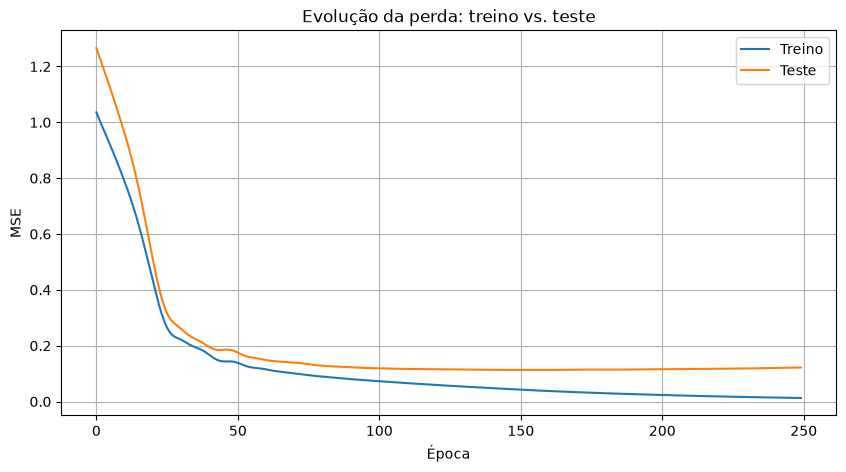

In [46]:

import matplotlib.pyplot as plt

num_epochs = 250

train_losses = []
test_losses = []

for epoch in range(num_epochs):
    # Treinamento: atualiza os pesos
    model.train()

    optimizer.zero_grad()

    y_pred_train = model(X_train_tensor)
    train_loss = criterion(y_pred_train, y_train_tensor)

    train_loss.backward()
    optimizer.step()

    train_losses.append(train_loss.item())

    # Avaliação: não atualiza os pesos
    model.eval()

    with torch.no_grad():
        y_pred_test = model(X_test_tensor)
        test_loss = criterion(y_pred_test, y_test_tensor)

    test_losses.append(test_loss.item())

    if (epoch + 1) % 20 == 0:
        print(
            f"Época [{epoch + 1}/{num_epochs}] "
            f"| Treino: {train_loss.item():.6f} "
            f"| Teste: {test_loss.item():.6f}"
        )

# Compara as curvas de perda
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Treino")
plt.plot(test_losses, label="Teste")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Evolução da perda: treino vs. teste")
plt.legend()
plt.grid(True)
plt.show()



In [47]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Gera previsões
model.eval()

with torch.no_grad():
    y_pred_scaled = model(X_test_tensor).cpu().numpy().reshape(-1)

# Desfaz a padronização e o logaritmo do alvo
y_pred_log = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

y_pred_price = np.expm1(y_pred_log)

# Valores reais em reais
y_true_price = y_test.to_numpy()

# Métricas
rmse = np.sqrt(mean_squared_error(y_true_price, y_pred_price))
mae = mean_absolute_error(y_true_price, y_pred_price)
r2 = r2_score(y_true_price, y_pred_price)

print(f"RMSE: R$ {rmse:,.2f}")
print(f"MAE:  R$ {mae:,.2f}")
print(f"R²:   {r2:.4f}")

RMSE: R$ 26,752.55
MAE:  R$ 16,492.65
R²:   0.9067
